# 06 - Evaluation of predictions and uncertainty

Evaluation of one training run from the validation predictions written by notebook 05
(`validation_predictions.csv` in the run folder). The run is chosen with `evaluation.run` in `configs/default.yaml`
(`latest` = most recent run of `training.representation`). Outputs go to `<run>/evaluation/`.

1. Classification and calibration metrics, deterministic pass and MC dropout mean.
2. Reliability diagram: are the probabilities calibrated?
3. Error rate against uncertainty: are the most uncertain predictions wrong more often?
4. Rejection curves: accuracy on the records kept after discarding the most uncertain ones, against random rejection
   and an oracle that discards the wrong predictions first.

Uncertainty measures (`evaluation.uncertainty_measures`): entropy of the deterministic prediction (baseline without
MC dropout), and, from the MC passes, standard deviation of the probability, predictive entropy and mutual information
(epistemic part). Each measure is judged on the prediction it refers to. A prediction is wrong when the probability,
thresholded at 0.5, disagrees with the label; calibration uses the prior-corrected probabilities.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from wqu.config import load_config
from wqu.evaluation.uncertainty_assessment import (
    REFERENCE_PREDICTION,
    error_detection_table,
    error_rate_tables,
    prediction_errors,
    rejection_curves,
    rejection_summary,
    retained_fractions,
)
from wqu.training.metrics import classification_metrics, reliability_table
from wqu.training.trainer import VALIDATION_PREDICTIONS_FILE, find_run_dir
from wqu.visualization import (
    apply_plot_style,
    plot_error_by_uncertainty,
    plot_rejection_curves,
    plot_reliability_diagram,
    save_figure,
)

CONFIG_PATH = Path("..") / "configs" / "default.yaml"

config = load_config(CONFIG_PATH)
label_column = config.columns.label
evaluation = config.evaluation
n_bins = config.training.calibration_bins
apply_plot_style()

run_dir = find_run_dir(config.training.runs_dir, config.training.representation, evaluation.run)
output_dir = run_dir / "evaluation"
output_dir.mkdir(exist_ok=True)
predictions = pd.read_csv(run_dir / VALIDATION_PREDICTIONS_FILE)
labels = predictions[label_column].to_numpy()
print(f"Run: {run_dir.name}; validation records: {len(predictions):,}; bad rate {labels.mean():.3f}")

Run: scalogram_20261111_095324; validation records: 400; bad rate 0.495


## 1. Metrics

AUC and balanced accuracy on the raw probabilities (threshold 0.5, equal cost of the two errors), ECE on the
prior-corrected probabilities.

In [2]:
PREDICTIONS = {"deterministic": "probability_deterministic", "mc_dropout": "probability_mean"}
metrics = {}
for name, column in PREDICTIONS.items():
    values = classification_metrics(predictions[column].to_numpy(), labels, n_bins)
    values["ece"] = classification_metrics(predictions[f"{column}_corrected"].to_numpy(), labels, n_bins)["ece"]
    values["error_rate"] = float(prediction_errors(predictions[column].to_numpy(), labels).mean())
    metrics[name] = values
metrics = pd.DataFrame(metrics)
metrics.to_csv(output_dir / "metrics.csv")
metrics.round(4)

,deterministic,mc_dropout
auc,0.8738,0.8739
balanced_accuracy,0.8074,0.8074
ece,0.0671,0.0507
error_rate,0.1925,0.1925


## 2. Reliability diagram

Records grouped in `training.calibration_bins` equal-width bins of the prior-corrected probability; in each bin the
observed share of bad records against the mean predicted probability. Points on the diagonal: calibrated; below:
over-confident towards bad; above: under-confident. Bottom: records per bin (bins with few records are noisy).

PosixPath('/Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/runs/scalogram_20261111_095324/evaluation/reliability_diagram.pdf')

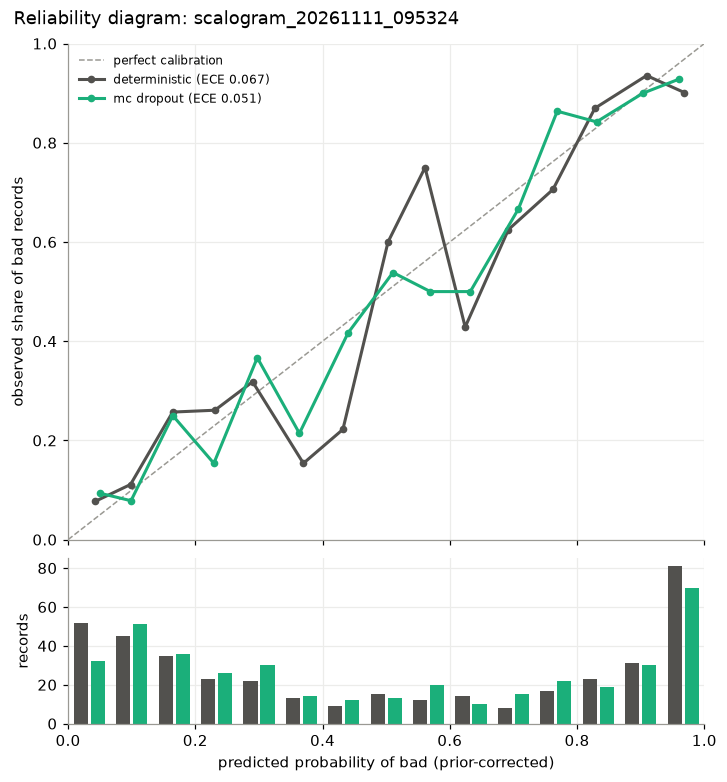

In [3]:
reliability = {name: reliability_table(predictions[f"{column}_corrected"].to_numpy(), labels, n_bins)
               for name, column in PREDICTIONS.items()}
pd.concat(reliability, names=["prediction", "bin"]).to_csv(output_dir / "reliability.csv")
figure = plot_reliability_diagram(reliability, metrics.loc["ece"].to_dict(), f"Reliability diagram: {run_dir.name}")
save_figure(figure, output_dir / "reliability_diagram.png")
save_figure(figure, output_dir / "reliability_diagram.pdf")

## 3. Error rate against uncertainty

Records sorted by each uncertainty measure and divided into `evaluation.error_groups` groups of equal size; error rate
in each group. An informative measure gives an error rate that grows from the least to the most uncertain group. The
error-detection AUC summarizes it: probability that a wrong prediction is more uncertain than a right one (0.5 =
useless, 1 = perfect).

In [4]:
measures = list(evaluation.uncertainty_measures)
detection = error_detection_table(predictions, label_column, measures)
detection.to_csv(output_dir / "error_detection.csv")
detection.round(4)

,prediction,error_rate,error_detection_auc
deterministic_entropy,probability_deterministic,0.1925,0.7183
probability_std,probability_mean,0.1925,0.6964
predictive_entropy,probability_mean,0.1925,0.7185
mutual_information,probability_mean,0.1925,0.6224


PosixPath('/Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/runs/scalogram_20261111_095324/evaluation/error_by_uncertainty.pdf')

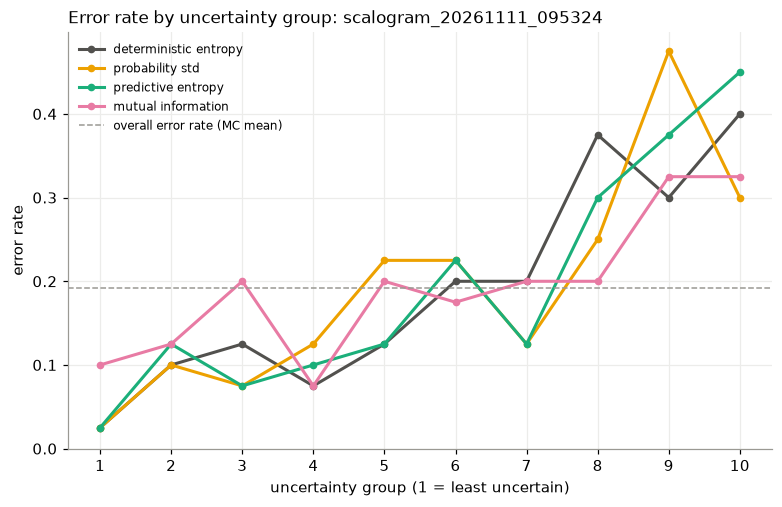

In [5]:
error_tables = error_rate_tables(predictions, label_column, measures, evaluation.error_groups)
pd.concat(error_tables, names=["measure", "group"]).to_csv(output_dir / "error_by_uncertainty.csv")
overall_error = float(prediction_errors(predictions[REFERENCE_PREDICTION].to_numpy(), labels).mean())
figure, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
plot_error_by_uncertainty(error_tables, overall_error, ax)
ax.set_title(f"Error rate by uncertainty group: {run_dir.name}", loc="left")
save_figure(figure, output_dir / "error_by_uncertainty.png")
save_figure(figure, output_dir / "error_by_uncertainty.pdf")

## 4. Rejection curves

The most uncertain records are discarded first (in practice: sent to manual review) and the metrics are computed on the
records kept. Random rejection (mean over `evaluation.random_repeats` orders) leaves the metrics unchanged on average;
the oracle discards the wrong predictions first and is the best achievable. The closer a measure is to the oracle, the
more useful it is for deciding which records to review.

PosixPath('/Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/runs/scalogram_20261111_095324/evaluation/rejection_curves.pdf')

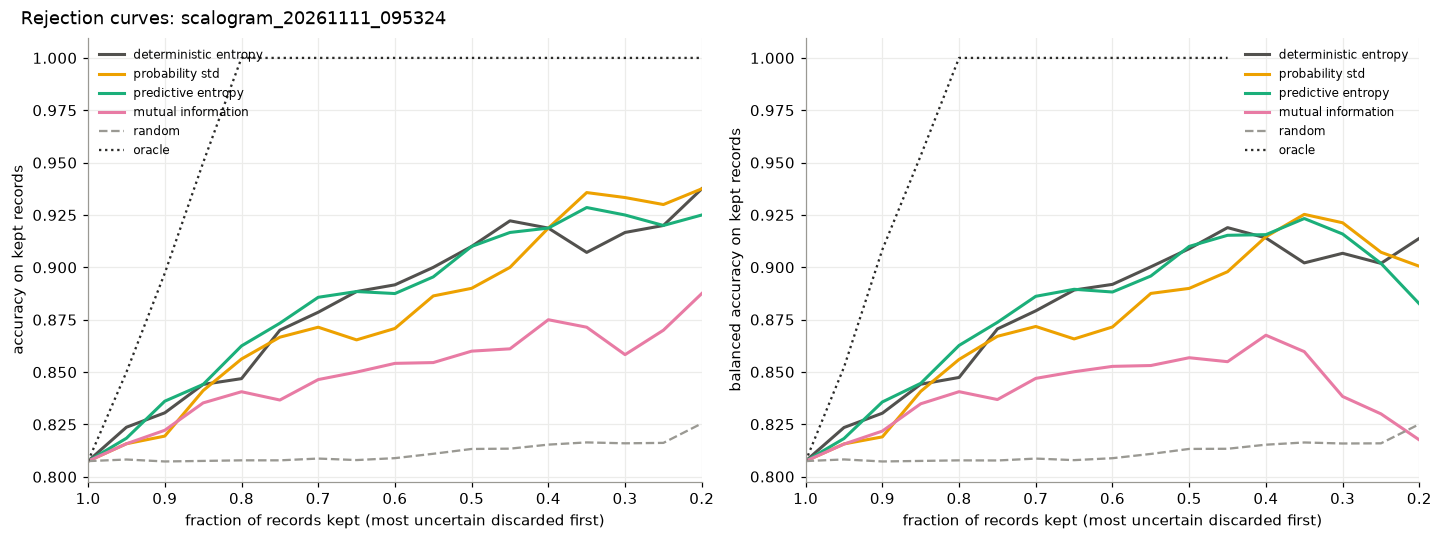

In [6]:
fractions = retained_fractions(evaluation.min_retained_fraction, evaluation.retained_step)
curves = rejection_curves(predictions, label_column, measures, fractions, evaluation.random_repeats,
                          evaluation.random_seed)
curves.to_csv(output_dir / "rejection_curves.csv", index=False)
figure, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
for ax, metric in zip(axes, ("accuracy", "balanced_accuracy")):
    plot_rejection_curves(curves, metric, ax)
figure.suptitle(f"Rejection curves: {run_dir.name}", x=0.01, ha="left")
save_figure(figure, output_dir / "rejection_curves.png")
save_figure(figure, output_dir / "rejection_curves.pdf")

In [7]:
summary = {metric: rejection_summary(curves, evaluation.reported_retained_fractions, metric)
           for metric in ("accuracy", "balanced_accuracy")}
summary = pd.concat(summary, names=["metric", "method"])
summary.to_csv(output_dir / "rejection_summary.csv")
summary.round(4)

retained_fraction                           1.0     0.9     0.8     0.7  \
metric            method                                                  
accuracy          deterministic_entropy  0.8075  0.8306  0.8469  0.8786   
                  probability_std        0.8075  0.8194  0.8562  0.8714   
                  predictive_entropy     0.8075  0.8361  0.8625  0.8857   
                  mutual_information     0.8075  0.8222  0.8406  0.8464   
                  random                 0.8075  0.8073  0.8079  0.8087   
                  oracle                 0.8075  0.8972  1.0000  1.0000   
balanced_accuracy deterministic_entropy  0.8074  0.8303  0.8473  0.8792   
                  probability_std        0.8074  0.8190  0.8560  0.8717   
                  predictive_entropy     0.8074  0.8356  0.8627  0.8861   
                  mutual_information     0.8074  0.8217  0.8406  0.8469   
                  random                 0.8074  0.8072  0.8078  0.8086   
                  oracle                 0.8074  0.9084  1.0000  1.0000   

retained_fraction                           0.5  
metric            method                         
accuracy          deterministic_entropy  0.9100  
                  probability_std        0.8900  
                  predictive_entropy     0.9100  
                  mutual_information     0.8600  
                  random                 0.8133  
                  oracle                 1.0000  
balanced_accuracy deterministic_entropy  0.9089  
                  probability_std        0.8899  
                  predictive_entropy     0.9100  
                  mutual_information     0.8568  
                  random                 0.8132  
                  oracle                 1.0000